# 02 - Wiener baseline 

1. DIV2K sanity check: synthetic blur, kernel KNOWN to the filter. Purpose: show the Wiener code is correct.
2. GoPro baseline: real blur, kernel UNKNOWN. One assumed linear-motion kernel + K, tuned on the VALIDATION pairs, applied once to the TEST pairs.

All numbers come from `results/tables/wiener_summary.json`. 

## 1. Get the code and the data

In [ ]:
%cd /content
!test -d C19_project || git clone https://github.com/zaynabahmad/C19_project.git
%cd ~/C19_project
!git pull
!pip3 install -q -r requirements.txt

[Errno 2] No such file or directory: '/content'
/home/zaynap/C19_project
Cloning into 'C19_project'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 25 (delta 6), reused 21 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 175.95 KiB | 16.00 KiB/s, done.
Resolving deltas: 100% (6/6), done.
[Errno 2] No such file or directory: '/content/C19_project'
/home/zaynap/C19_project
^C
ERROR: Ignored the following versions that require a different python version: 2.3.0 Requires-Python >=3.11; 2.3.1 Requires-Python >=3.11; 2.3.2 Requires-Python >=3.11; 2.3.3 Requires-Python >=3.11; 2.3.4 Requires-Python >=3.11; 2.3.5 Requires-Python >=3.11; 2.4.0 Requires-Python >=3.11; 2.4.0rc1 Requires-Python >=3.11; 2.4.1 Requires-Python >=3.11; 2.4.2 Requires-Python >=3.11; 2.4.3 Requires-Python >=3.11; 2.4.4 Requires-Python >=3.11; 2.4.5 Requires-Python >=3.11; 2.4.6 Requires-Python >=3.11; 

In [10]:
# Download only what is missing (data is wiped when the Colab session ends)
!test -d data/raw/DIV2K_valid_HR || python3 src/fetch_data.py --dataset div2k
!test -d data/raw/train || python3 src/fetch_data.py --dataset gopro

## 2. Re-create the subset lists and check they match the committed ones

In [11]:
!python3 -m src.make_subset
!git status --short data/subsets
print("If nothing is listed above, the subset lists are identical to the committed ones (reproducible).")

GoPro root: data/raw (blur folder: blur)
  train sequences: 22 (val held out: ['GOPR0372_07_00', 'GOPR0374_11_01', 'GOPR0881_11_00']), test sequences: 11
  pairs -> train: 365, val: 56, test: 223
DIV2K: 25 of 100 images selected (seed 42)
 M data/subsets/gopro_subset.json
If nothing is listed above, the subset lists are identical to the committed ones (reproducible).


## 3. Quick test first 

In [12]:
!python3 -m src.wiener_baseline --stage div2k --limit 3
!python3 -m src.wiener_baseline --stage gopro --limit 5 --tune-n 5

  0804.png: blurred 22.70 dB -> K=0.001: 18.41, K=0.01: 25.47, K=0.03: 25.24, K=0.1: 21.85
  0805.png: blurred 24.80 dB -> K=0.001: 18.75, K=0.01: 26.49, K=0.03: 26.68, K=0.1: 22.71
  0812.png: blurred 24.05 dB -> K=0.001: 19.17, K=0.01: 26.48, K=0.03: 26.55, K=0.1: 23.21
{
 "n_images": 3,
 "kernel_length": 15,
 "noise_sigma": 0.01,
 "seed": 42,
 "limit": 3,
 "mean_psnr_blurred": 23.85238215111363,
 "mean_ssim_blurred": 0.6014591058095297,
 "mean_psnr_K0.001": 18.778297408823956,
 "mean_ssim_K0.001": 0.29288755853970844,
 "mean_psnr_K0.01": 26.144454334258786,
 "mean_ssim_K0.01": 0.6232823332150778,
 "mean_psnr_K0.03": 26.156527353634733,
 "mean_ssim_K0.03": 0.7162661552429199,
 "mean_psnr_K0.1": 22.590648514675195,
 "mean_ssim_K0.1": 0.7057793736457825
} 
(15s)
Tuning on 5 validation pairs, 96 configs (length, angle, K) ...
Best on validation: {'length': 3, 'angle_deg': 45, 'K': 0.001, 'val_mean_psnr': 25.28577186055971}  (blurred input: 25.50 dB)  [57s]
Evaluating on 5 TEST pairs ...

## 4. Full runs 

In [13]:
!python3 -m src.wiener_baseline --stage div2k

  0804.png: blurred 22.70 dB -> K=0.001: 18.41, K=0.01: 25.47, K=0.03: 25.24, K=0.1: 21.85
  0805.png: blurred 24.80 dB -> K=0.001: 18.75, K=0.01: 26.49, K=0.03: 26.68, K=0.1: 22.71
  0812.png: blurred 24.05 dB -> K=0.001: 19.17, K=0.01: 26.48, K=0.03: 26.55, K=0.1: 23.21
  0814.png: blurred 24.54 dB -> K=0.001: 18.91, K=0.01: 26.61, K=0.03: 26.83, K=0.1: 24.45
  0815.png: blurred 28.36 dB -> K=0.001: 18.76, K=0.01: 28.09, K=0.03: 30.09, K=0.1: 26.47
  0818.png: blurred 23.69 dB -> K=0.001: 18.81, K=0.01: 26.03, K=0.03: 25.96, K=0.1: 21.96
  0826.png: blurred 21.50 dB -> K=0.001: 18.59, K=0.01: 24.08, K=0.03: 23.56, K=0.1: 21.00
  0828.png: blurred 15.54 dB -> K=0.001: 17.89, K=0.01: 19.42, K=0.03: 18.10, K=0.1: 16.73
  0829.png: blurred 24.84 dB -> K=0.001: 18.65, K=0.01: 25.78, K=0.03: 26.29, K=0.1: 24.25
  0830.png: blurred 22.96 dB -> K=0.001: 19.56, K=0.01: 25.64, K=0.03: 25.16, K=0.1: 22.15
  0832.png: blurred 24.19 dB -> K=0.001: 18.95, K=0.01: 26.75, K=0.03: 27.05, K=0.1: 23.76

In [14]:
!python3 -m src.wiener_baseline --stage gopro

Tuning on 20 validation pairs, 96 configs (length, angle, K) ...
Best on validation: {'length': 3, 'angle_deg': 45, 'K': 0.001, 'val_mean_psnr': 24.49363959724144}  (blurred input: 24.61 dB)  [208s]
Evaluating on 223 TEST pairs ...
  25/223
  50/223
  75/223
  100/223
  125/223
  150/223
  175/223
  200/223
{
 "n_test": 223,
 "blur_dir": "blur",
 "seed": 42,
 "limit": 0,
 "tuned_on_n_val_pairs": 20,
 "best_config": {
  "length": 3,
  "angle_deg": 45,
  "K": 0.001,
  "val_mean_psnr": 24.49363959724144
 },
 "mean_psnr_blurred": 25.550528099945154,
 "mean_ssim_blurred": 0.7769421388482833,
 "mean_psnr_wiener": 25.263936840768498,
 "mean_ssim_wiener": 0.7661242738967519
}


## 5.results

{
 "div2k_sanity_check": {
  "n_images": 25,
  "kernel_length": 15,
  "noise_sigma": 0.01,
  "seed": 42,
  "limit": 0,
  "mean_psnr_blurred": 23.281061685963163,
  "mean_ssim_blurred": 0.6203922832012176,
  "mean_psnr_K0.001": 18.815835306600285,
  "mean_ssim_K0.001": 0.29733085036277773,
  "mean_psnr_K0.01": 25.509618828247486,
  "mean_ssim_K0.01": 0.608883171081543,
  "mean_psnr_K0.03": 25.472718938839066,
  "mean_ssim_K0.03": 0.7093392014503479,
  "mean_psnr_K0.1": 22.45661334197497,
  "mean_ssim_K0.1": 0.712207202911377
 },
 "gopro_test": {
  "n_test": 223,
  "blur_dir": "blur",
  "seed": 42,
  "limit": 0,
  "tuned_on_n_val_pairs": 20,
  "best_config": {
   "length": 3,
   "angle_deg": 45,
   "K": 0.001,
   "val_mean_psnr": 24.49363959724144
  },
  "mean_psnr_blurred": 25.550528099945154,
  "mean_ssim_blurred": 0.7769421388482833,
  "mean_psnr_wiener": 25.263936840768498,
  "mean_ssim_wiener": 0.7661242738967519
 }
}


,length,angle_deg,K,val_mean_psnr
4,3,45,0.001,24.493640
12,3,135,0.001,24.489332
5,3,45,0.010,24.485378
13,3,135,0.010,24.480993
1,3,0,0.010,24.430270
9,3,90,0.010,24.365721
6,3,45,0.030,24.248073
14,3,135,0.030,24.244196


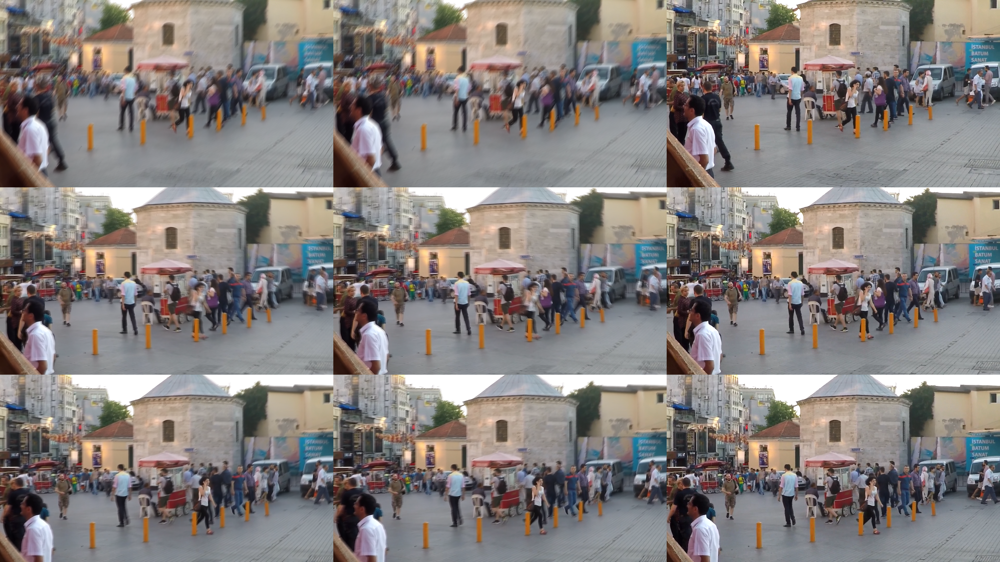

In [15]:
import json, pandas as pd
from IPython.display import Image, display
print(json.dumps(json.load(open("results/tables/wiener_summary.json")), indent=1))
display(pd.read_csv("results/tables/wiener_gopro_tuning.csv").sort_values("val_mean_psnr", ascending=False).head(8))
display(Image("results/figures/wiener_gopro_examples.png", width=700))